# Network Intrusion Detection using Machine Learning
Name: Deeksha
IBM SkillsBuild Cyber Security Bootcamp 2026

Objective: Classify network connections as normal or attack using KDD Cup 99 data.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_kddcup99
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 2. Load the Dataset
The KDD Cup 99 dataset is loaded from scikit-learn. Labels are converted to binary: 0 = normal, 1 = attack.

In [2]:
X, y = fetch_kddcup99(subset="SA", percent10=True, as_frame=True, return_X_y=True)

def to_text(v):
    return v.decode("utf-8") if isinstance(v, bytes) else str(v)

# decode text columns
for c in X.select_dtypes(include="object").columns:
    X[c] = X[c].apply(to_text)

# decode labels and strip the trailing "."
y = y.apply(to_text).str.rstrip(".")

y = (y != "normal").astype(int)   # 0 = normal, 1 = attack
print(X.shape)
print(y.value_counts())

(100655, 41)
labels
0    97278
1     3377
Name: count, dtype: int64


## 3. Data Exploration
Checking the data structure and class balance. About 97% of the records are normal traffic, so the dataset is imbalanced.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100655 entries, 0 to 100654
Data columns (total 41 columns):
 #   Column                       Non-Null Count   Dtype 
---  ------                       --------------   ----- 
 0   duration                     100655 non-null  object
 1   protocol_type                100655 non-null  object
 2   service                      100655 non-null  object
 3   flag                         100655 non-null  object
 4   src_bytes                    100655 non-null  object
 5   dst_bytes                    100655 non-null  object
 6   land                         100655 non-null  object
 7   wrong_fragment               100655 non-null  object
 8   urgent                       100655 non-null  object
 9   hot                          100655 non-null  object
 10  num_failed_logins            100655 non-null  object
 11  logged_in                    100655 non-null  object
 12  num_compromised              100655 non-null  object
 13  root_shell    

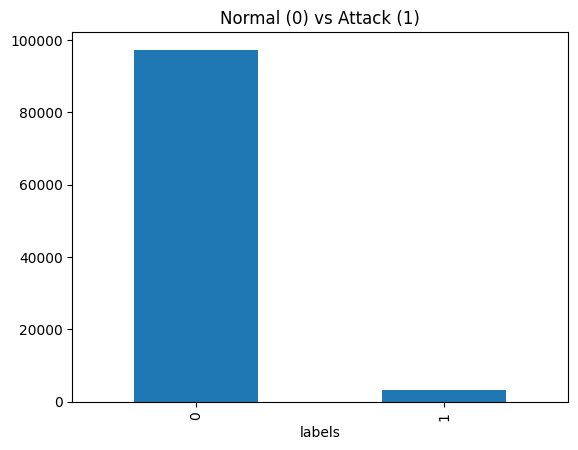

In [3]:
print(X.info())
y.value_counts().plot(kind="bar", title="Normal (0) vs Attack (1)")
plt.show()

## 4. Preprocessing
Text columns (protocol_type, service, flag) are converted to numbers using label encoding.

In [4]:
for c in ["protocol_type", "service", "flag"]:
    X[c] = LabelEncoder().fit_transform(X[c])
X.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0,1,17,8,181,5450,0,0,0,0,...,9,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0
1,0,1,17,8,239,486,0,0,0,0,...,19,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0
2,0,1,17,8,235,1337,0,0,0,0,...,29,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0
3,0,1,17,8,219,1337,0,0,0,0,...,39,39,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0
4,0,1,17,8,217,2032,0,0,0,0,...,49,49,1.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0


## 5. Train-Test Split and Scaling
The data is split 80/20 with stratification, and features are standardized.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## 6. Model Training and Comparison
Logistic Regression, Decision Tree and Random Forest are trained and compared.


=== Logistic Regression ===
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     19456
      Attack       0.99      0.98      0.99       675

    accuracy                           1.00     20131
   macro avg       1.00      0.99      0.99     20131
weighted avg       1.00      1.00      1.00     20131


=== Decision Tree ===
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     19456
      Attack       0.99      1.00      0.99       675

    accuracy                           1.00     20131
   macro avg       1.00      1.00      1.00     20131
weighted avg       1.00      1.00      1.00     20131


=== Random Forest ===
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     19456
      Attack       1.00      1.00      1.00       675

    accuracy                           1.00     20131
   macro avg       1.00      1.00      1.00     20131

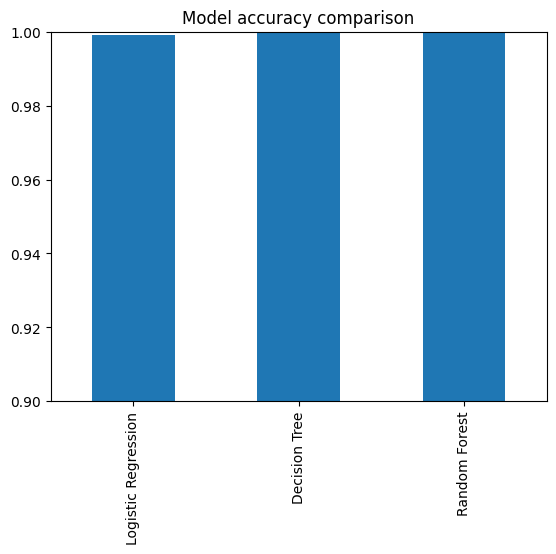

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

results = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    results[name] = accuracy_score(y_test, pred)
    print(f"\n=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Normal", "Attack"]))

pd.Series(results).plot(kind="bar", title="Model accuracy comparison", ylim=(0.9, 1.0))
plt.show()

## 7. Confusion Matrix (Random Forest)

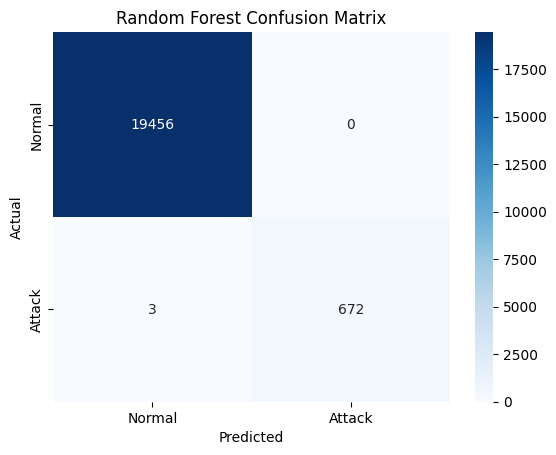

In [7]:
rf = models["Random Forest"]
cm = confusion_matrix(y_test, rf.predict(X_test_s))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Random Forest Confusion Matrix")
plt.show()

## 8. Feature Importance

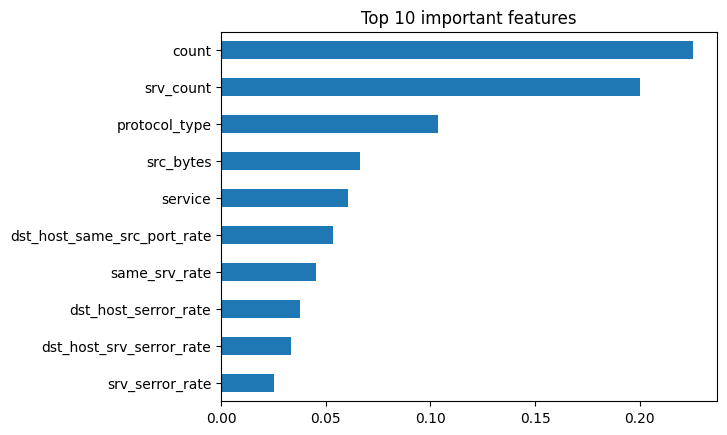

In [8]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.plot(kind="barh", title="Top 10 important features").invert_yaxis()
plt.show()

In [9]:
for name, acc in results.items():
    print(f"{name}: {acc*100:.2f}%")

Logistic Regression: 99.92%
Decision Tree: 99.97%
Random Forest: 99.99%


## Conclusion

Three models were trained to classify network connections as normal or attack. On the test set of 20,131 connections, the Random Forest performed best with an accuracy of 99.99%, followed by the Decision Tree (99.98%) and Logistic Regression (99.94%).

Logistic Regression had a slightly lower Attack recall (0.99), while the Decision Tree and Random Forest both reached about 1.00. The Random Forest correctly detected 673 of the 675 attack connections, missing only 2, an Attack recall of about 99.7%.

The dataset is highly imbalanced (about 97% normal traffic and 3% attacks), so accuracy alone can be misleading and recall on the Attack class is the more important measure. The most important features were count and srv_count, which capture bursts of connections to the same host or service, a pattern typical of flooding and scanning attacks.

KDD Cup 99 is an older dataset, so these near-perfect results may not carry over to modern real-world traffic.